# Ladder pairs: what changes between pinned and frustrated graphs

Ladders with crossings, labelled by the **exact ground-state degeneracy** of the blockade
(MIS) Hamiltonian: **pinned** = unique ground state, **frustrated** = degenerate.

The dataset keeps only **RRWP-2-blind groups**: graphs with the same pooled RRWP-2
signature (sorted entries of $M$, $M^2$, $M = D^{-1}A$) that contain both labels. This
notebook shows one such group, why a short random walk cannot tell its members apart,
what the ideal ground state looks like, the atom registers, and what the AFM/FM quench
measures on them (released data `ladder_afm` / `ladder_fm`).

In [1]:
import os
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

from qgf.data import load
from qgf.synthetic.blind import blind_pool
from qgf.synthetic.features import rrwp_matrices
from qgf.synthetic.ladder import gs_correlations_dp, ladder, ladder_layout, unit_disk_positions

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
DATA = Path(os.environ.get("QGF_DATA", ROOT / "data" / "processed"))

# two categorical slots (validated: CVD dE 24.7); text and axes stay in neutral ink
PIN, FRU, INK, MUTED, EDGE = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#c3c2b7"
CLS = {1: ("pinned", PIN), 0: ("frustrated", FRU)}
mpl.rcParams.update(
    {
        "figure.dpi": 120,
        "font.size": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": EDGE,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
    }
)

In [2]:
def draw_ladder(ax, m, cross, y, partner=(), node=26, lw=1.6):
    """Ladder drawing; crossings absent from ``partner`` are drawn thick, nodes shaded by
    their ground-state occupation (black = occupied, white = empty, grey = degenerate)."""
    G = ladder(m, cross)
    occ, _, count = gs_correlations_dp(G)
    pos = ladder_layout(G)
    rails = [(u, v) for u, v in G.edges() if not (u < m and v == u + m + 1)]
    nx.draw_networkx_edges(G, pos, edgelist=rails, ax=ax, edge_color=EDGE, width=lw)
    name, col = CLS[y]
    for c in cross:
        moved = c not in partner
        ax.plot([c, c + 1], [1, 0], color=col if moved else INK, lw=3.2 if moved else lw, zorder=1)
    nx.draw_networkx_nodes(
        G,
        pos,
        ax=ax,
        node_size=node,
        node_color=occ,
        cmap="Greys",
        vmin=0,
        vmax=1,
        edgecolors=INK,
        linewidths=0.6,
    )
    ax.set_title(
        f"{name}: crossings {list(cross)}, degeneracy {count}", loc="left", color=col, fontsize=9
    )
    ax.set_axis_off()


def rrwp_gap(m, a, b, K=8):
    """max |difference| of the sorted entries of M^k between two ladders, k = 1..K."""
    Pa = rrwp_matrices(nx.to_numpy_array(ladder(m, a), nodelist=range(2 * m)), K)
    Pb = rrwp_matrices(nx.to_numpy_array(ladder(m, b), nodelist=range(2 * m)), K)
    return np.array([np.abs(np.sort(x.ravel()) - np.sort(z.ravel())).max() for x, z in zip(Pa, Pb)])

## The blind pool

Every open ladder with 9-13 rungs (18-26 atoms) is enumerated; a blind group at horizon
$K$ shares its pooled RRWP-$K$ signature and holds both labels.

In [3]:
recs, gid = blind_pool(9, 13, [2, 3])
y_pool = np.array([r["y"] for r in recs])
for K in (2, 3):
    g = gid[K]
    sizes = sorted({2 * r["m"] for r, gg in zip(recs, g) if gg >= 0})
    print(
        f"K={K}: {int((g >= 0).sum())} graphs in {len(set(g[g >= 0]))} blind groups, "
        f"{sizes} atoms (of {len(recs)} ladders)"
    )

K=2: 936 graphs in 153 blind groups, [18, 20, 22, 24, 26] atoms (of 7931 ladders)
K=3: 178 graphs in 42 blind groups, [22, 24, 26] atoms (of 7931 ladders)


## One blind group

The two graphs have the same size and the same number of crossings; one crossing sits one
cell further (thick, coloured). The sorted entries of $M^k$ are bit-identical for
$k \le 2$ (shaded) and only differ from $k = 3$ on, so any permutation-invariant RRWP-2
readout is at chance.

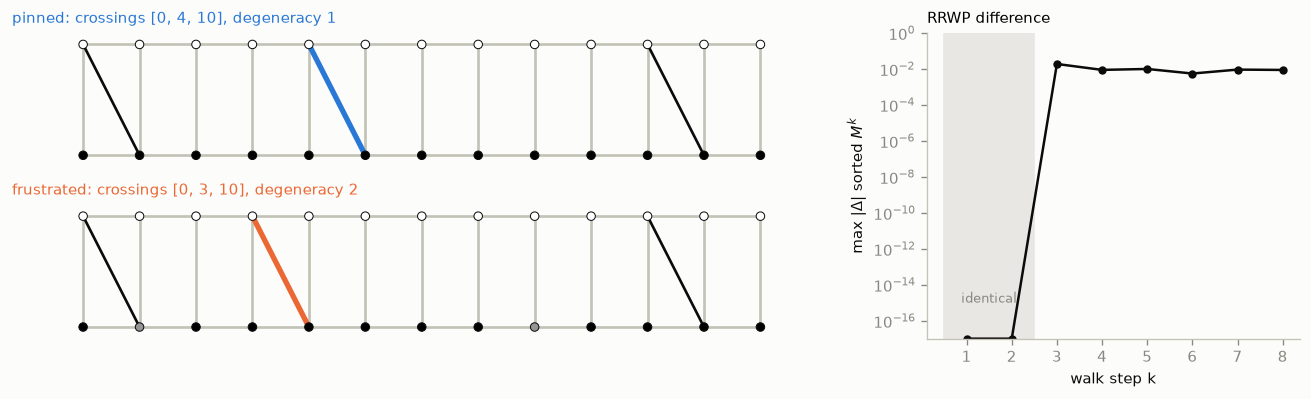

In [4]:
groups = sorted(set(gid[2][(gid[2] >= 0) & (gid[3] < 0)]))
grp = groups[len(groups) // 2]
idx = np.nonzero(gid[2] == grp)[0]
p = next(i for i in idx if y_pool[i] == 1)
f = next(i for i in idx if y_pool[i] == 0)
m = recs[p]["m"]
fig = plt.figure(figsize=(11, 3.4))
gs = fig.add_gridspec(2, 2, width_ratios=[2.2, 1])
draw_ladder(fig.add_subplot(gs[0, 0]), m, recs[p]["cross"], 1, recs[f]["cross"])
draw_ladder(fig.add_subplot(gs[1, 0]), m, recs[f]["cross"], 0, recs[p]["cross"])
ax = fig.add_subplot(gs[:, 1])
gap = rrwp_gap(m, recs[p]["cross"], recs[f]["cross"])
ks = np.arange(1, len(gap) + 1)
ax.semilogy(ks, np.maximum(gap, 1e-17), "o-", color=INK, ms=4, lw=1.5)
ax.axvspan(0.5, 2.5, color="#e8e7e3", zorder=0)
ax.text(1.5, 1e-15, "identical", ha="center", fontsize=8, color=MUTED)
ax.set(ylim=(1e-17, 1), xticks=ks, xlabel="walk step k", ylabel="max |Δ| sorted $M^k$")
ax.set_title("RRWP difference", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

### Ideal ground state

Pinned: every crossing agrees with one of the two alternating ground states, so it is
unique and $C_{ij} = 0$ exactly. Frustrated: the crossings disagree, the ground state is
degenerate and strongly correlated. This is the quantity the quench is sensitive to.

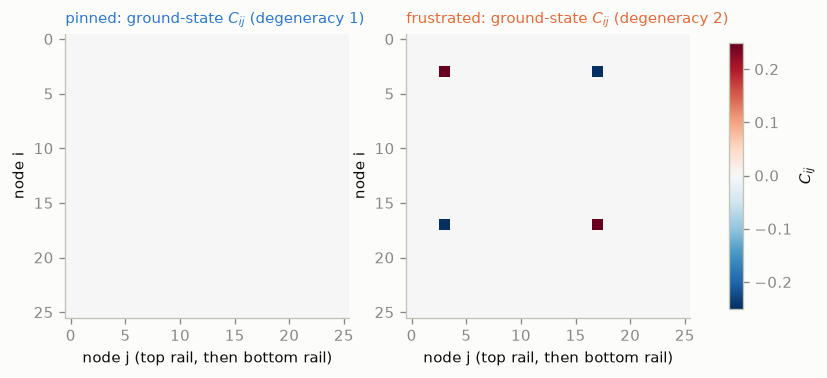

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.6))
for ax, i in zip(axes, (p, f)):
    _, C, count = gs_correlations_dp(ladder(recs[i]["m"], recs[i]["cross"]))
    im = ax.imshow(C, cmap="RdBu_r", vmin=-0.25, vmax=0.25)
    name, col = CLS[y_pool[i]]
    ax.set_title(
        f"{name}: ground-state $C_{{ij}}$ (degeneracy {count})", loc="left", color=col, fontsize=9
    )
    ax.set(xlabel="node j (top rail, then bottom rail)", ylabel="node i")
fig.colorbar(im, ax=axes, shrink=0.8, label="$C_{ij}$")
plt.show()

### Atom registers

Unit-disk layout with $r_{NN} = 5.01\,\mu$m: square cells, a crossing cell is a rhombus
of two equilateral triangles, so the strip steps up at every crossing. Every edge is at
$r_{NN}$, every non-edge at $\ge \sqrt{2}\, r_{NN}$ (coupling $\le J_{NN}/8$).

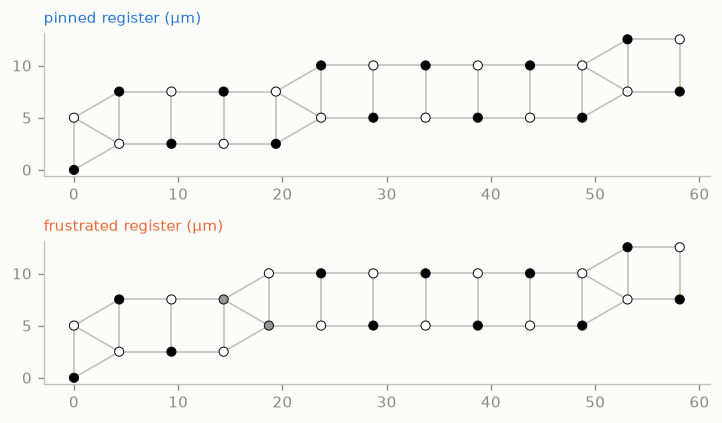

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(9, 3.6))
for ax, i in zip(axes, (p, f)):
    G = ladder(recs[i]["m"], recs[i]["cross"])
    pos = unit_disk_positions(G)
    for u, v in G.edges():
        ax.plot(*pos[[u, v]].T, color=EDGE, lw=1, zorder=1)
    occ = gs_correlations_dp(G)[0]
    ax.scatter(*pos.T, c=occ, cmap="Greys", vmin=0, vmax=1, s=30, edgecolors=INK, lw=0.6, zorder=2)
    ax.set_aspect("equal")
    name, col = CLS[y_pool[i]]
    ax.set_title(f"{name} register (µm)", loc="left", color=col, fontsize=9)
plt.tight_layout()
plt.show()

## What the quench measures

The released features of one pinned/frustrated pair of the same blind group: mean AFM
occupation over the 4 µs quench, and the AFM connected correlation $C_{ij}$ at the last
time. Features are stored time-major (`[T, N]`, `[T, N, N]`, ZZ convention $4C$).

394 graphs; blind group 6: initial_id 25 (pinned), 24 (frustrated)


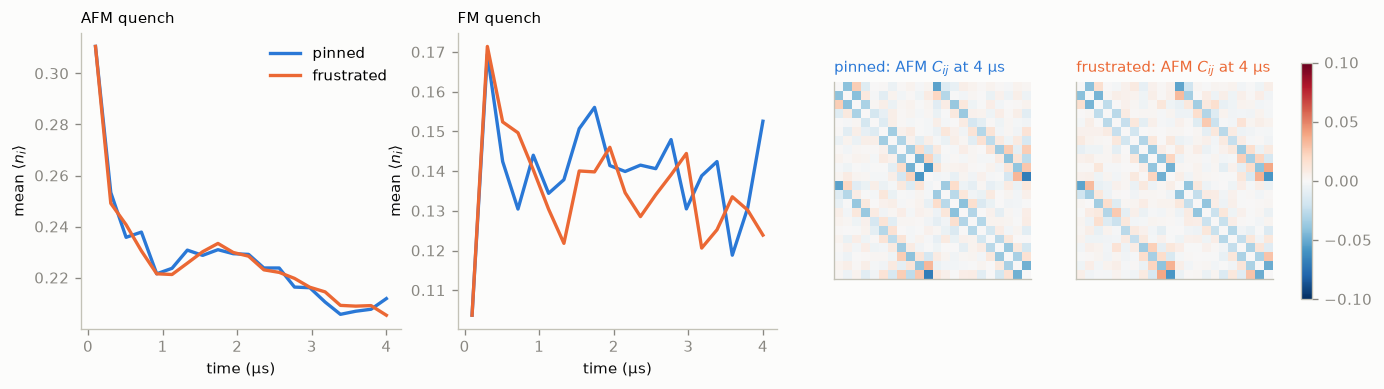

In [7]:
afm, meta = load("ladder_afm", root=DATA)
fm, _ = load("ladder_fm", root=DATA)
t_us = np.asarray(meta["times_ns"]) / 1000
by_group = {}
for k, g in enumerate(afm):
    by_group.setdefault(int(g.blind_group), []).append(k)
grp = next(gr for gr, ks in by_group.items() if afm[ks[0]].num_nodes == 22)
kp = next(k for k in by_group[grp] if int(afm[k].y) == 1)
kf = next(k for k in by_group[grp] if int(afm[k].y) == 0)
print(
    f"{len(afm)} graphs; blind group {grp}: initial_id {int(afm[kp].initial_id)} (pinned), "
    f"{int(afm[kf].initial_id)} (frustrated)"
)

fig, ax = plt.subplots(1, 4, figsize=(14, 3.2), gridspec_kw={"width_ratios": [1.3, 1.3, 1, 1]})
for data, title, a in ((afm, "AFM", ax[0]), (fm, "FM", ax[1])):
    for k in (kp, kf):
        name, col = CLS[int(data[k].y)]
        a.plot(t_us, data[k].occupation.mean(1), color=col, lw=2, label=name)
    a.set(xlabel="time (µs)", ylabel=r"mean $\langle n_i \rangle$")
    a.set_title(f"{title} quench", loc="left", fontsize=9)
ax[0].legend(frameon=False)
for a, k in zip(ax[2:], (kp, kf)):
    C = afm[k].twobody_features[-1].numpy() / meta["zz_scale_applied"]
    im = a.imshow(C, cmap="RdBu_r", vmin=-0.1, vmax=0.1)
    name, col = CLS[int(afm[k].y)]
    a.set_title(f"{name}: AFM $C_{{ij}}$ at 4 µs", loc="left", color=col, fontsize=9)
    a.set_xticks([])
    a.set_yticks([])
fig.colorbar(im, ax=ax[2:], shrink=0.8)
plt.show()

## Summary

- Partners share size, crossing count, pooled RRWP-2 and ring features (bit-identical);
  only a crossing's **parity** differs. RRWP-2 is at chance by construction.
- The ideal ground state separates them perfectly ($C_{ij} \equiv 0$ when pinned).
- The AFM/FM quench of the paper picks up the difference from the dynamics: AUC 0.91
  (AFM) and 0.94 (AFM+FM) with a logistic regression, against 0.68 for the best classical
  combination (`reproduce_table.ipynb`).